# Análise Exploratória dos Dados Inicial

In [2]:
import sys
from pathlib import Path

# Garante que a raiz do projeto está no sys.path
ROOT = Path().resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


## O que encontrar neste Notebook?

Este notebook tem como objetivo conduzir uma análise exploratória inicial dos dados (EDA) no contexto de serviços de telecomunicações, com foco na compreensão da estrutura, qualidade e comportamento das variáveis disponíveis.

A análise será organizada de forma estruturada por grupos de variáveis — como demográficas, geográficas, financeiras e de relacionamento — permitindo uma leitura mais coerente sob a ótica de negócio. Para cada grupo, serão realizadas análises univariadas e bivariadas em relação à variável alvo (churn), com o intuito de identificar padrões, distribuições, possíveis inconsistências e indícios preliminares de associação.

Adicionalmente, ao final do notebook, será conduzida uma análise multivariada com abordagem exploratória, incluindo o uso de modelos interpretáveis, como árvores de decisão, para capturar interações entre variáveis e aprofundar a identificação de possíveis drivers de churn.

Este material tem como finalidade não apenas descrever os dados, mas também gerar hipóteses analíticas e direcionar as próximas etapas do desenvolvimento de modelos preditivos.

# Entendimento do Negócio

O presente dataset refere-se a um cenário fictício de uma empresa de telecomunicações que oferece serviços de telefonia e internet para seus clientes. O principal objetivo é analisar o fenômeno de customer churn, ou seja, a evasão de clientes — quando um usuário deixa de utilizar os serviços da empresa.

A base de dados foi estruturada para capturar múltiplas dimensões do comportamento dos clientes, incluindo características demográficas, serviços contratados, informações de faturamento e tempo de relacionamento com a empresa. A variável alvo indica se o cliente cancelou ou não o serviço em um determinado período.

Do ponto de vista de negócio, a análise de churn é altamente estratégica, uma vez que a retenção de clientes tende a ser significativamente mais econômica do que a aquisição de novos. Nesse contexto, compreender os fatores que influenciam a evasão permite direcionar ações mais eficazes de retenção, como campanhas segmentadas, melhorias na experiência do cliente e ajustes na oferta de serviços.

Assim, este dataset possibilita a investigação de padrões de comportamento associados ao churn, bem como o desenvolvimento de modelos preditivos capazes de identificar clientes com maior propensão a cancelar os serviços.

# Importando as Bibliotecas

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Pacotes Matemáticos
from scipy import stats


from sklearn.tree import DecisionTreeClassifier

# Params
plt.rcParams['figure.dpi'] = 400
pd.set_option('display.max_columns', None)


# Importando a Base

In [2]:
# Dataset obtido em https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset
df = pd.read_excel('../data/raw/Telco_customer_churn.xlsx')
df.head()

NameError: name 'pd' is not defined

# Funções Auxiliares

In [5]:
# Funções utilitárias extraídas para src/utils
from experiments.utils.eda import freq_table, sanity_check, taxa_churn_categoria
from experiments.utils.plots import (
    boxplots_target_binaria,
    grid_cat_freq_event_rate,
    plot_univariate,
)
from experiments.utils.stats import (
    AnaliseIV,
    calculate_vif,
    chi2_analysis,
    classify_vif,
    cramers_v,
)


ModuleNotFoundError: No module named 'experiments'

# Dicionário de Dados (Metadados)

A tabela abaixo descreve as variáveis disponíveis no dataset, incluindo tipo, categoria e interpretação no contexto de negócio.


| Variável            | Tipo        | Categoria              | Descrição                                                                 |
|--------------------|------------|-----------------------|--------------------------------------------------------------------------|
| CustomerID         | Categórica | Identificação         | Identificador único do cliente                                           |
| Count              | Numérica   | Técnica               | Variável constante (valor fixo = 1) utilizada para contagem              |
| Country            | Categórica | Geográfica            | País do cliente                                                          |
| State              | Categórica | Geográfica            | Estado do cliente                                                        |
| City               | Categórica | Geográfica            | Cidade do cliente                                                        |
| Zip Code           | Numérica   | Geográfica            | Código postal                                                            |
| Lat Long           | Categórica | Geográfica            | Coordenadas geográficas combinadas                                       |
| Latitude           | Numérica   | Geográfica            | Latitude                                                                 |
| Longitude          | Numérica   | Geográfica            | Longitude                                                                |
| Gender             | Categórica | Demográfica           | Gênero do cliente                                                        |
| Senior Citizen     | Categórica | Demográfica           | Indica se o cliente é idoso                                              |
| Partner            | Categórica | Demográfica           | Indica se possui parceiro(a)                                             |
| Dependents         | Categórica | Demográfica           | Indica se possui dependentes                                             |
| Tenure Months      | Numérica   | Relacionamento        | Tempo de permanência do cliente (meses)                                 |
| Phone Service      | Categórica | Serviços              | Possui serviço telefônico                                                |
| Multiple Lines     | Categórica | Serviços              | Possui múltiplas linhas                                                  |
| Internet Service   | Categórica | Serviços              | Tipo de serviço de internet                                              |
| Online Security    | Categórica | Serviços              | Serviço de segurança online                                              |
| Online Backup      | Categórica | Serviços              | Serviço de backup online                                                 |
| Device Protection  | Categórica | Serviços              | Proteção de dispositivos                                                 |
| Tech Support       | Categórica | Serviços              | Suporte técnico                                                          |
| Streaming TV       | Categórica | Serviços              | Serviço de streaming de TV                                               |
| Streaming Movies   | Categórica | Serviços              | Serviço de streaming de filmes                                           |
| Contract           | Categórica | Relacionamento        | Tipo de contrato                                                         |
| Paperless Billing  | Categórica | Relacionamento        | Fatura digital                                                           |
| Payment Method     | Categórica | Relacionamento        | Método de pagamento                                                      |
| Monthly Charges    | Numérica   | Financeira            | Valor mensal cobrado                                                     |
| Total Charges      | Numérica*  | Financeira            | Valor total cobrado (pode exigir conversão de tipo)                     |
| Churn Label        | Categórica | Target                | Indica churn (Yes/No)                                                   |
| Churn Value        | Binária    | Target                | Indicador numérico de churn (1 = churn)                                 |
| Churn Score        | Numérica   | Score                 | Score preditivo de churn (derivado)                                     |
| CLTV               | Numérica   | Financeira/Score      | Lifetime value estimado do cliente                                      |
| Churn Reason       | Categórica | Pós-Churn          | Motivo do cancelamento (apenas para clientes churn)                     |

---

⚠️ **Notas importantes:**

- *Total Charges* está como string e deve ser convertido para numérico antes das análises.
- *Churn Score*, *CLTV* e *Churn Reason* podem introduzir **data leakage**, pois são derivados ou conhecidos após o evento de churn.
- *Churn Label* e *Churn Value* representam a mesma informação (usar apenas uma como target).

# Sanity Check

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [7]:
sanity_check(df)

NameError: name 'sanity_check' is not defined

- A coluna `churn reason` possui 73,46% de dados faltantes. Isso é explicado por causa dessa variável ser responsável por armazenar a justificativa de abandono do cliente.
- Inconsistencias de dados foram encontradas nas colunas `Multiple Lines`, `Online Security`, `Online Backup`, `Device Protection`, `Text Support`, `Streaming TV`, `Streaming Movies`, `Payment Methods`
- Não temos dados duplicados, ou seja, cada linha do nosso dataframe representa um cliente.
- Coluna `count` é uma coluna criada para manipulação de filtros em dashboards e pode ser descartada.
- Coluna `Total Charges` está como object ao invés de float.

## Tratamento dos Dados

In [8]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

In [9]:
df['Total Charges'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: Total Charges
Non-Null Count  Dtype  
--------------  -----  
7032 non-null   float64
dtypes: float64(1)
memory usage: 55.2 KB


# Separando as variáveis

## Classificação das Variáveis

As variáveis do dataset foram organizadas em grupos de acordo com sua natureza e papel no contexto de negócio, permitindo uma análise exploratória estruturada e orientada à interpretação dos fatores associados ao churn.

### 🔹 Variáveis Geográficas
- Country
- State
- City
- Zip Code
- Latitude
- Longitude
- Lat Long

### 🔹 Variáveis Demográficas
- Gender
- Senior Citizen
- Partner
- Dependents

### 🔹 Variáveis de Relacionamento com o Cliente
- Tenure Months
- Contract
- Paperless Billing
- Payment Method

### 🔹 Variáveis de Serviços Contratados
- Phone Service
- Multiple Lines
- Internet Service
- Online Security
- Online Backup
- Device Protection
- Tech Support
- Streaming TV
- Streaming Movies

### 🔹 Variáveis Financeiras
- Monthly Charges
- Total Charges

### 🔹 Variáveis Derivadas / Score
- Churn Score
- CLTV

### 🔹 Variáveis Relacionadas ao Churn (Pós-Evento ⚠️)
- Churn Label
- Churn Value
- Churn Reason

### 🔹 Variáveis Técnicas / Identificação
- CustomerID
- Count

---

⚠️ **Observação importante:**  
Variáveis como *Churn Score*, *CLTV* e *Churn Reason* podem conter **informação derivada ou posterior ao evento de churn**, devendo ser utilizadas com cautela em análises preditivas para evitar *data leakage*.

In [57]:
target = 'Churn Label'
num_vars = [col for col in df.columns if df[col].dtype in ['int64', 'float64']]
cat_vars = [col for col in df.columns if df[col].dtype in ['str', 'object', 'category']]

## Variáveis Numéricas

In [58]:
num_vars

['Count',
 'Zip Code',
 'Latitude',
 'Longitude',
 'Tenure Months',
 'Monthly Charges',
 'Total Charges',
 'Churn Value',
 'Churn Score',
 'CLTV']

In [12]:
geo_vars = ['Zip Code', 'Latitude', 'Longitude']

In [13]:
# removendo variáveis geofráficas que não serão utilizadas agoras
for col in geo_vars:
    num_vars.remove(col)

# removendo a coluna Count - utilizada apenas para manipulação de filtros em dashboards
num_vars.remove('Count')

In [14]:
num_vars

['Tenure Months',
 'Monthly Charges',
 'Total Charges',
 'Churn Value',
 'Churn Score',
 'CLTV']

## Variáveis Categóricas

In [15]:
cat_vars

['CustomerID',
 'Country',
 'State',
 'City',
 'Lat Long',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Churn Label',
 'Churn Reason']

In [16]:
# são colunas que não vão impactar nas análises nesse primeiro momento
drop_cols = ['CustomerID', 'Country', 'State', 'Lat Long', 'Churn Label', 'Churn Reason']

for col in drop_cols:
    cat_vars.remove(col)

In [17]:
cat_vars

['City',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method']

# Análise de Outliers

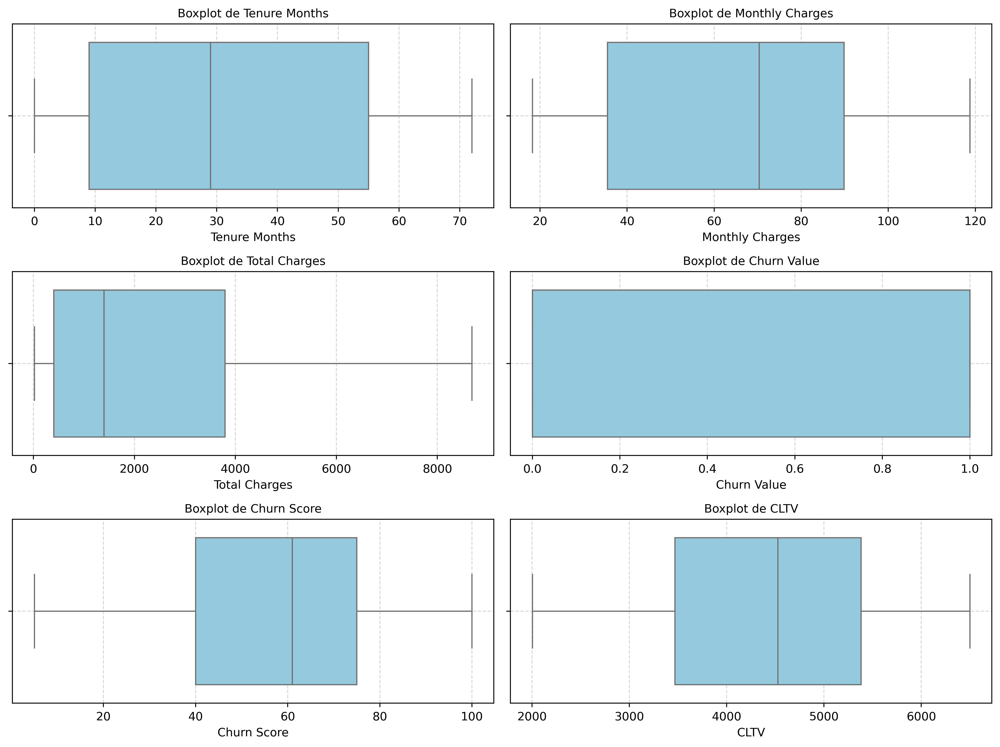

In [18]:
import math

n_cols = 2
n_rows = math.ceil(len(num_vars) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(12, 3 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_vars):
    sns.boxplot(x=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot de {col}', fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.5)

# Remove eixos vazios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Variáveis Geográficas

In [19]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [20]:
vars_geograficas = [
    'Country',
    'State',
    'City',
    'Zip Code',
    'Lat Long',
    'Latitude',
    'Longitude'
]

In [21]:
df[vars_geograficas].nunique()

Country         1
State           1
City         1129
Zip Code     1652
Lat Long     1652
Latitude     1652
Longitude    1651
dtype: int64

In [22]:
df[['Country', 'State']].value_counts()

Country        State     
United States  California    7043
Name: count, dtype: int64

- O Dataset avalia serviços apenas do estado da Califórnia nos Estados Unidos. Isso pode imputar limitações e vieses ao modelo de predição de Churn.

### Tabelas de Frequência

In [23]:
# frequência absoluta
freq_abs = df['City'].value_counts(dropna=False)

# frequência relativa (%)
freq_rel = df['City'].value_counts(normalize=True, dropna=False) * 100

# criando DataFrame consolidado
tabela_cidades = pd.DataFrame({
    'Cidade': freq_abs.index,
    'Frequência Absoluta': freq_abs.values,
    'Frequência Relativa (%)': freq_rel.values
})

# ordenando (garantia)
tabela_cidades = tabela_cidades.sort_values(by='Frequência Absoluta', ascending=False)

# frequência acumulada (%)
tabela_cidades['Frequência Acumulada (%)'] = tabela_cidades['Frequência Relativa (%)'].cumsum()

# top 10 cidades
top10_cidades = tabela_cidades.head(10)

# resetando índice
top10_cidades = top10_cidades.reset_index(drop=True)

top10_cidades

# arredondando as colunas de porcentagem para 2 casas decimais
top10_cidades.style.format({
    'Frequência Relativa (%)': '{:.2f}',
    'Frequência Acumulada (%)': '{:.2f}'
})

,Cidade,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,Los Angeles,305,4.33,4.33
1,San Diego,150,2.13,6.46
2,San Jose,112,1.59,8.05
3,Sacramento,108,1.53,9.58
4,San Francisco,104,1.48,11.06
5,Fresno,64,0.91,11.97
6,Long Beach,60,0.85,12.82
7,Oakland,52,0.74,13.56
8,Stockton,44,0.62,14.18
9,Bakersfield,40,0.57,14.75


- O Dataset mostra um padrão clássico de: alta cardinalidade + baixa concentração → baixo poder preditivo bruto
- Não seria recomendado usar a "Cidade" sem fazer devidos tratamentos de redução de cardinalidade, encoding ou análise de churn condicional

### Mapa de Calor - Taxa de Churn por Cidade

In [24]:
# garantir tipos corretos
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')

# remover nulos
df_geo = df.dropna(subset=['Latitude', 'Longitude', 'Churn Value'])

In [25]:
df_top_regions = (
    df_geo
    .groupby(['City'])
    .agg(
        total_clientes=('Churn Value', 'count'),
        churn_rate=('Churn Value', 'mean')
    )
    .query('total_clientes >= 30')
    .sort_values('churn_rate', ascending=False)
    .head(10)
)

df_top_regions

,total_clientes,churn_rate
City,,
San Diego,150,0.333333
Glendale,40,0.325000
Pasadena,30,0.300000
San Francisco,104,0.298077
Los Angeles,305,0.295082
Berkeley,32,0.281250
Stockton,44,0.272727
San Jose,112,0.258929
Oakland,52,0.250000


In [26]:
from folium import Map
from folium.plugins import HeatMap

# base do mapa (centro médio)
mapa = Map(
    location=[df_geo['Latitude'].mean(), df_geo['Longitude'].mean()],
    zoom_start=5
)

# dados para heatmap
heat_data = [
    [row['Latitude'], row['Longitude'], row['Churn Value']]
    for _, row in df_geo.iterrows()
]

# adiciona heatmap
HeatMap(heat_data, radius=8).add_to(mapa)

mapa

ModuleNotFoundError: No module named 'folium'

- O Churn não está concentrado, ele é sistêmico nas áreas urbanas da Califórnia
- Problema não é "cidade específica"

In [27]:
# =========================
# REGION MAPPING (4 CLASSES)
# =========================

NORCAL_COUNTIES = {
    "Alameda","Contra Costa","Marin","Napa","San Francisco","San Mateo",
    "Santa Clara","Solano","Sonoma","Sacramento","Yolo","Placer","El Dorado",
    "Nevada","Yuba","Sutter","Butte","Shasta","Humboldt","Mendocino","Lake",
    "Del Norte","Trinity","Tehama","Siskiyou","Modoc","Lassen","Plumas","Sierra","Alpine","Amador","Calaveras","Tuolumne"
}

SOCAL_COUNTIES = {
    "Los Angeles","Orange","San Diego","Ventura"
}

CENTRAL_COUNTIES = {
    "Fresno","Kern","Kings","Tulare","Madera",
    "San Joaquin","Stanislaus","Merced",
    "Monterey","San Luis Obispo","Santa Barbara","Santa Cruz"
}

DESERT_COUNTIES = {
    "Riverside","San Bernardino","Imperial","Inyo"
}


def classify_region_from_county(county):
    if county in NORCAL_COUNTIES:
        return "norcal"
    elif county in SOCAL_COUNTIES:
        return "socal"
    elif county in CENTRAL_COUNTIES:
        return "central"
    elif county in DESERT_COUNTIES:
        return "socal"  # desert incluído como socal
    else:
        return "other"

In [28]:
df['City_enc'] = df['City'].apply(classify_region_from_county)

In [29]:
df['City_enc'].value_counts()

City_enc
other      6058
socal       552
norcal      289
central     144
Name: count, dtype: int64

In [30]:
df.groupby(['City_enc']).agg(
        total_clientes=('Churn Value', 'count'),
        churn_rate=('Churn Value', 'mean')
    )

,total_clientes,churn_rate
City_enc,,
central,144,0.277778
norcal,289,0.269896
other,6058,0.261803
socal,552,0.298913


- Fora SoCal, o churn é relativamente homogêneo
- SoCal possui diferença de churn de ~14% relativo → forte evidência de efeito regional
- "other" domina o dataset representando 85%, pode "mascarar" padrões mais específicos

# Variáveis Demográficas e Familiares

In [31]:
vars_demograficas = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents'
]

In [32]:
df[vars_demograficas].describe(include='object')

,Gender,Senior Citizen,Partner,Dependents
count,7043,7043,7043,7043
unique,2,2,2,2
top,Male,No,No,No
freq,3555,5901,3641,5416


In [33]:
for col in vars_demograficas:
    print(f"valores únicos em {col}: {df[col].unique()}")

valores únicos em Gender: ['Male' 'Female']
valores únicos em Senior Citizen: ['No' 'Yes']
valores únicos em Partner: ['No' 'Yes']
valores únicos em Dependents: ['No' 'Yes']


In [34]:
for col in vars_demograficas:
    print(f"\n📊 Tabela de frequência para {col}:\n")
    display(freq_table(df, col))


📊 Tabela de frequência para Gender:



NameError: name 'freq_table' is not defined

In [35]:
for var in vars_demograficas:
    print(f'\n📊 Variável: {var}')
    display(taxa_churn_categoria(df, var))


📊 Variável: Gender


NameError: name 'taxa_churn_categoria' is not defined

In [36]:
grid_cat_freq_event_rate(
    df,
    cat_vars=vars_demograficas,
    target='Churn Value',
    n_cols=2
)

NameError: name 'grid_cat_freq_event_rate' is not defined

### Distribuição
- Gênero: Praticamente perfeita (balanceada)
- Idoso: Classe minoritária relevante (16%)
- Casado: Quase balanceado
- Dependentes: Moderadamente desbalanceado
#### Dataset
- População majoritariamente não idosa
- Predominantemente sem dependentes
- Estado civil equilibrado
- gênero irrelevante do ponto de vista de distribuição
#### Potencial Preditivo
- Gênero: provavelmente irrelevante
- Idoso: forte candidato a driver, alta chance de ser feature relevante
- Partner: sinal comportamental indireto
- Dependentes: forte indicador de estabilidade, feature com alto poder explicativo
#### Interações
- Idoso + com/sem dependentes → risco ou retenção?
- Com/sem partner + com/sem dependentes → perfil mais estável/volátil?
- SoCal + sem dependentes → churn muito alto?

# Tipos de Serviços


In [ ]:
vars_servicos = [
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies'
]

In [ ]:
df[vars_servicos].describe(include='object')

,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies
count,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,3,3,3,3,3,3,3,3
top,Yes,No,Fiber optic,No,No,No,No,No,No
freq,6361,3390,3096,3498,3088,3095,3473,2810,2785


In [ ]:
for col in vars_servicos:
    print(f"valores únicos em {col}: {df[col].unique()}")

valores únicos em Phone Service: ['Yes' 'No']
valores únicos em Multiple Lines: ['No' 'Yes' 'No phone service']
valores únicos em Internet Service: ['DSL' 'Fiber optic' 'No']
valores únicos em Online Security: ['Yes' 'No' 'No internet service']
valores únicos em Online Backup: ['Yes' 'No' 'No internet service']
valores únicos em Device Protection: ['No' 'Yes' 'No internet service']
valores únicos em Tech Support: ['No' 'Yes' 'No internet service']
valores únicos em Streaming TV: ['No' 'Yes' 'No internet service']
valores únicos em Streaming Movies: ['No' 'Yes' 'No internet service']


In [ ]:
for col in vars_servicos:
    print(f"\n📊 Tabela de frequência para {col}:\n")
    display(freq_table(df, col))


📊 Tabela de frequência para Phone Service:



,Phone Service,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,Yes,6361,90.32,90.32
1,No,682,9.68,100.00



📊 Tabela de frequência para Multiple Lines:



,Multiple Lines,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,3390,48.13,48.13
1,Yes,2971,42.18,90.32
2,No phone service,682,9.68,100.00



📊 Tabela de frequência para Internet Service:



,Internet Service,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,Fiber optic,3096,43.96,43.96
1,DSL,2421,34.37,78.33
2,No,1526,21.67,100.00



📊 Tabela de frequência para Online Security:



,Online Security,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,3498,49.67,49.67
1,Yes,2019,28.67,78.33
2,No internet service,1526,21.67,100.00



📊 Tabela de frequência para Online Backup:



,Online Backup,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,3088,43.84,43.84
1,Yes,2429,34.49,78.33
2,No internet service,1526,21.67,100.00



📊 Tabela de frequência para Device Protection:



,Device Protection,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,3095,43.94,43.94
1,Yes,2422,34.39,78.33
2,No internet service,1526,21.67,100.00



📊 Tabela de frequência para Tech Support:



,Tech Support,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,3473,49.31,49.31
1,Yes,2044,29.02,78.33
2,No internet service,1526,21.67,100.00



📊 Tabela de frequência para Streaming TV:



,Streaming TV,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,2810,39.90,39.90
1,Yes,2707,38.44,78.33
2,No internet service,1526,21.67,100.00



📊 Tabela de frequência para Streaming Movies:



,Streaming Movies,Frequência Absoluta,Frequência Relativa (%),Frequência Acumulada (%)
0,No,2785,39.54,39.54
1,Yes,2732,38.79,78.33
2,No internet service,1526,21.67,100.00


In [ ]:
for var in vars_servicos:
    print(f'\n📊 Variável: {var}')
    display(taxa_churn_categoria(df, var))


📊 Variável: Phone Service


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Phone Service,,,,
Yes,6361,1699,0.267096,26.709637
No,682,170,0.249267,24.926686



📊 Variável: Multiple Lines


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Multiple Lines,,,,
Yes,2971,850,0.286099,28.609896
No,3390,849,0.250442,25.044248
No phone service,682,170,0.249267,24.926686



📊 Variável: Internet Service


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Internet Service,,,,
Fiber optic,3096,1297,0.418928,41.892765
DSL,2421,459,0.189591,18.959108
No,1526,113,0.074050,7.404980



📊 Variável: Online Security


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Online Security,,,,
No,3498,1461,0.417667,41.766724
Yes,2019,295,0.146112,14.611194
No internet service,1526,113,0.074050,7.404980



📊 Variável: Online Backup


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Online Backup,,,,
No,3088,1233,0.399288,39.928756
Yes,2429,523,0.215315,21.531494
No internet service,1526,113,0.074050,7.404980



📊 Variável: Device Protection


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Device Protection,,,,
No,3095,1211,0.391276,39.127625
Yes,2422,545,0.225021,22.502064
No internet service,1526,113,0.074050,7.404980



📊 Variável: Tech Support


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Tech Support,,,,
No,3473,1446,0.416355,41.635474
Yes,2044,310,0.151663,15.166341
No internet service,1526,113,0.074050,7.404980



📊 Variável: Streaming TV


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Streaming TV,,,,
No,2810,942,0.335231,33.523132
Yes,2707,814,0.300702,30.070188
No internet service,1526,113,0.074050,7.404980



📊 Variável: Streaming Movies


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Streaming Movies,,,,
No,2785,938,0.336804,33.680431
Yes,2732,818,0.299414,29.941435
No internet service,1526,113,0.074050,7.404980


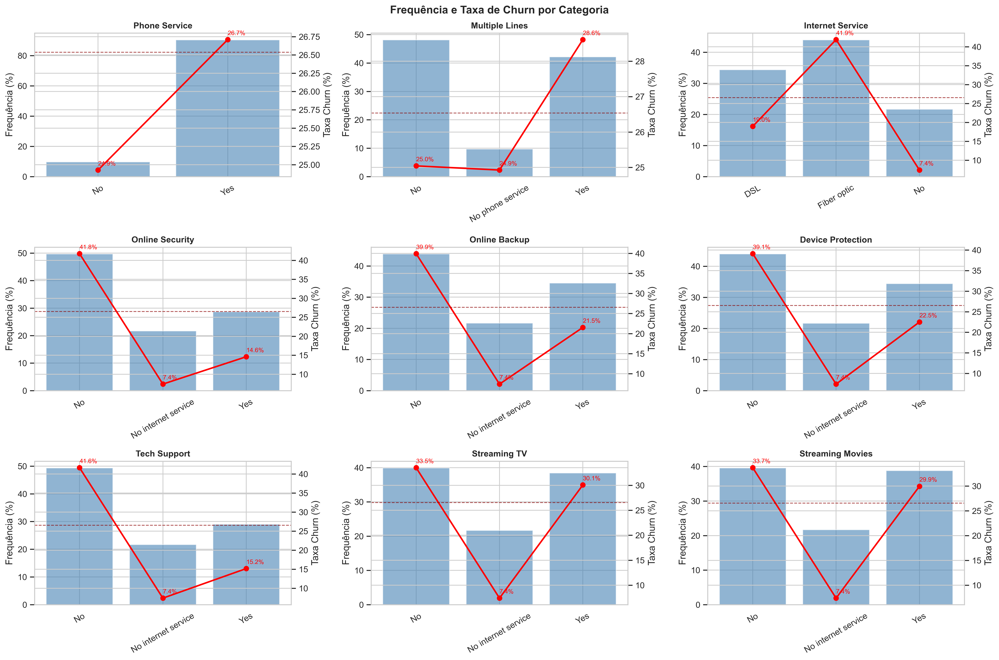

In [ ]:
grid_cat_freq_event_rate(
    df,
    cat_vars=vars_servicos,
    target='Churn Value',
    n_cols=3
)

### Distribuição
- Phone Service: Quase todo mundo possui telefone
- Multiple Lines: Distribuição quase balanceada
- Internet Service: Possui boa separação entre perfis
- Online Security: Forte assimetris
- Online Backup: Pouco mais adotado, mas ainda minoritário
- Device Protection: Semelhante ao Backup
- Tech Support: baixa penetração
- Streaming TV: Quase balanceado
- Streaming Movies: Quase balanceado
#### Conclusão
- "No Internet service" e "Internet Service" = "No" gera colinearidade, redundância e possível vazamento indireto de informação
- A maioria não contrata serviços de: Online Security, Tech Support, Device Protection e Online Backup
- É possível notar que a maioria dos clientes não possui serviços adicionais, logo, possui baixo engajamento com a empresa
- Hipótese: Sem serviços adicionais (especialmente Online Security e Tech Support), maior a probabilidade de Churn
- O churn está mais ligado ao nível de engajamento com os serviços do que a fatores demográficos.


# Variáveis Financeiras

### Contrato e Faturamento

In [37]:
vars_contrato_pagamento = [
    'Contract',
    'Paperless Billing',
    'Payment Method'
]

In [38]:
df[vars_contrato_pagamento].describe(include='object')

,Contract,Paperless Billing,Payment Method
count,7043,7043,7043
unique,3,2,4
top,Month-to-month,Yes,Electronic check
freq,3875,4171,2365


In [39]:
for col in vars_contrato_pagamento:
    print(f"valores únicos em {col}: {df[col].unique()}")

valores únicos em Contract: ['Month-to-month' 'Two year' 'One year']
valores únicos em Paperless Billing: ['Yes' 'No']
valores únicos em Payment Method: ['Mailed check' 'Electronic check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [40]:
for col in vars_contrato_pagamento:
    print(f"\n📊 Tabela de frequência para {col}:\n")
    display(freq_table(df, col))


📊 Tabela de frequência para Contract:



NameError: name 'freq_table' is not defined

In [ ]:
for var in vars_contrato_pagamento:
    print(f'\n📊 Variável: {var}')
    display(taxa_churn_categoria(df, var))


📊 Variável: Contract


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Contract,,,,
Month-to-month,3875,1655,0.427097,42.709677
One year,1473,166,0.112695,11.269518
Two year,1695,48,0.028319,2.831858



📊 Variável: Paperless Billing


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Paperless Billing,,,,
Yes,4171,1400,0.335651,33.565092
No,2872,469,0.163301,16.330084



📊 Variável: Payment Method


,Total Clientes,Qtd Churn,Taxa Churn,Taxa Churn (%)
Payment Method,,,,
Electronic check,2365,1071,0.452854,45.285412
Mailed check,1612,308,0.191067,19.106700
Bank transfer (automatic),1544,258,0.167098,16.709845
Credit card (automatic),1522,232,0.152431,15.243101


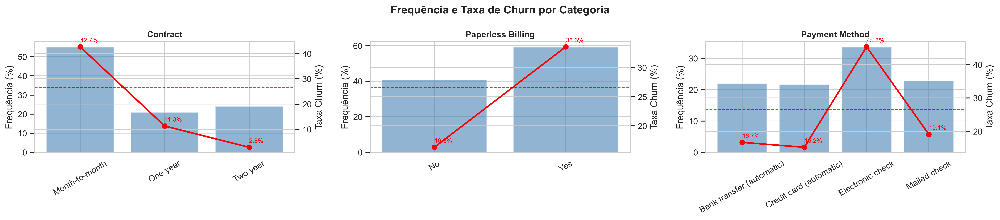

In [ ]:
grid_cat_freq_event_rate(
    df,
    cat_vars=vars_contrato_pagamento,
    target='Churn Value',
    n_cols=3
)

### Distribuição
- Contract: Mais da metade dos clientes não tem fidelização
- Paperless Billing: A maioria usa faturamento digital
- Payment Method: Razoavelmente equilibrada com leve destaque para Eletronic Check
#### Insight
- Contrato é o maior driver potencial de churn. 55% dos clientes estão em month-to-month significando baixa barreira de saída
- Método de pagamento é proxy de maturidade/engajamento financeiro. Pagamentos automáticos estão associados à maior conveniência, menor fricção e maior retenção
- Paperless Billing com Eletronic check pode indicar comportamento específico
#### Conclusão
- A empresa depende fortemente de clientes sem contrato longo gerando receita instável e alta rotatividade

### Receita e Monetização

In [41]:
vars_receita = [
    'Monthly Charges',
    'Total Charges',
    'Tenure Months'
]

In [42]:
df[vars_receita].describe()

,Monthly Charges,Total Charges,Tenure Months
count,7043.000000,7032.000000,7043.000000
mean,64.761692,2283.300441,32.371149
std,30.090047,2266.771362,24.559481
min,18.250000,18.800000,0.000000
25%,35.500000,401.450000,9.000000
50%,70.350000,1397.475000,29.000000
75%,89.850000,3794.737500,55.000000
max,118.750000,8684.800000,72.000000


In [43]:
# subplots num_vars
for col in vars_receita:
    plot_univariate(df, col)

NameError: name 'plot_univariate' is not defined

- Monthly charges: KDE mostra dois grupos bem definidos, QQ plot confirma uma distribuição não gaussiana
- Monthly charges: preço mensal está segmentando clientes em tiers de produto
- Total charges: Fortemente assimétrica à direita, QQ plot indica Heavy tail distribution
- Total Charges: é altamente correlacionado com Tenure, pode causar overweight em árvores
- Tenure: Bimodal, QQ plot mostra forte desvio da normalidade
- Tenure: Provável top 3 feature do modelo.
#### Conclusão
- Existe uma segmentação clara entre clientes novos e antigos, "básico" e "premium"
- Possuim relações não lineares com churn
- Variáveis altamente informativas, especialmente Tenure

In [44]:
boxplots_target_binaria(df, 'Churn Label', vars_receita, n_cols=1)

NameError: name 'boxplots_target_binaria' is not defined

- O churn está concentrado em valores mais altos nos pagamentos mensais
- Clientes que pagam mais, tendem ao churn
- Clientes que churnam têm baixo valor acumulado, eles churnam cedo no ciclo de vida
- Outliers altos em churn (Yes) existem, logo, churn tardio acontece mas é raro
- Quanto menor o tenure, maior o churn
- O Churn acontece principalmente nos primeiros meses de vida do cliente

# CLTV - Valor do Cliente

In [45]:
df['CLTV'].describe()

count    7043.000000
mean     4400.295755
std      1183.057152
min      2003.000000
25%      3469.000000
50%      4527.000000
75%      5380.500000
max      6500.000000
Name: CLTV, dtype: float64

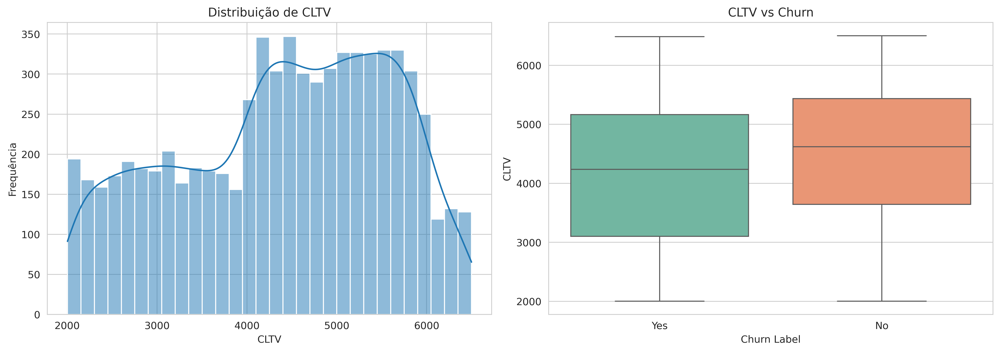

In [46]:
# ===============================
# Configuração de estilo
# ===============================
sns.set_style("whitegrid")

# ===============================
# Criação do subplot
# ===============================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ===============================
# 1. Histograma (distribuição)
# ===============================
sns.histplot(
    data=df,
    x='CLTV',
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribuição de CLTV')
axes[0].set_xlabel('CLTV')
axes[0].set_ylabel('Frequência')

# ===============================
# 2. Boxplot vs Churn
# ===============================
sns.boxplot(
    data=df,
    x='Churn Label',
    y='CLTV',
    hue='Churn Label',
    palette="Set2",
    ax=axes[1]
)

axes[1].set_title('CLTV vs Churn')
axes[1].set_xlabel('Churn Label')
axes[1].set_ylabel('CLTV')

# ===============================
# Ajuste final
# ===============================
plt.tight_layout()
plt.show()

- A base de clientes tem valor relativamente homogêneo (sem causa extrema)
- Clientes que churnam têm CLTV menor
- CLTV tem poder preditivo moderado por conta da diferença de ~300-500 no valor médio. É uma separação visível, mas não extrema

# Churn Score

In [47]:
df['Churn Score'].describe()

count    7043.000000
mean       58.699418
std        21.525131
min         5.000000
25%        40.000000
50%        61.000000
75%        75.000000
max       100.000000
Name: Churn Score, dtype: float64

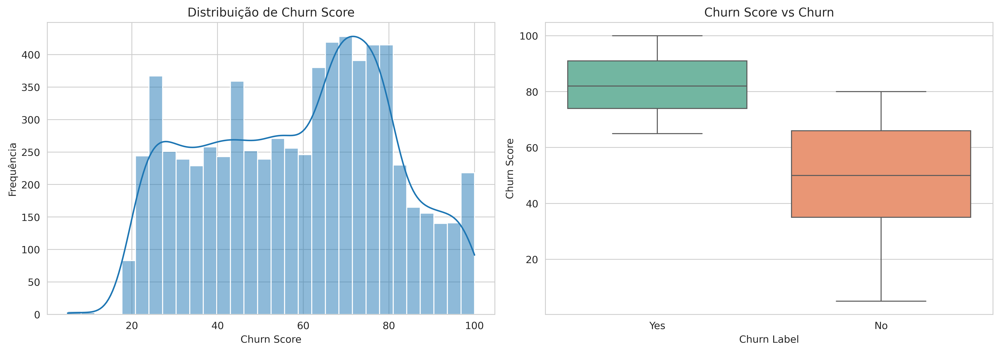

In [48]:
# ===============================
# Configuração de estilo
# ===============================
sns.set_style("whitegrid")

# ===============================
# Criação do subplot
# ===============================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ===============================
# 1. Histograma (distribuição)
# ===============================
sns.histplot(
    data=df,
    x='Churn Score',
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribuição de Churn Score')
axes[0].set_xlabel('Churn Score')
axes[0].set_ylabel('Frequência')

# ===============================
# 2. Boxplot vs Churn
# ===============================
sns.boxplot(
    data=df,
    x='Churn Label',
    y='Churn Score',
    hue='Churn Label',
    palette="Set2",
    ax=axes[1]
)

axes[1].set_title('Churn Score vs Churn')
axes[1].set_xlabel('Churn Label')
axes[1].set_ylabel('Churn Score')

# ===============================
# Ajuste final
# ===============================
plt.tight_layout()
plt.show()

- O score já está segmentando clientes em níveis de risco
- O churn = 'Yes' está concentrada em valores altos, com a mediana ~80+
- O churn = 'No' está disperso, incui valores baixos e médios, com a mediana ~50
- O Churn Score separa MUITO bem as classes

# Taxa de Churn

In [49]:
df['Churn Label'].value_counts(normalize=True)

Churn Label
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

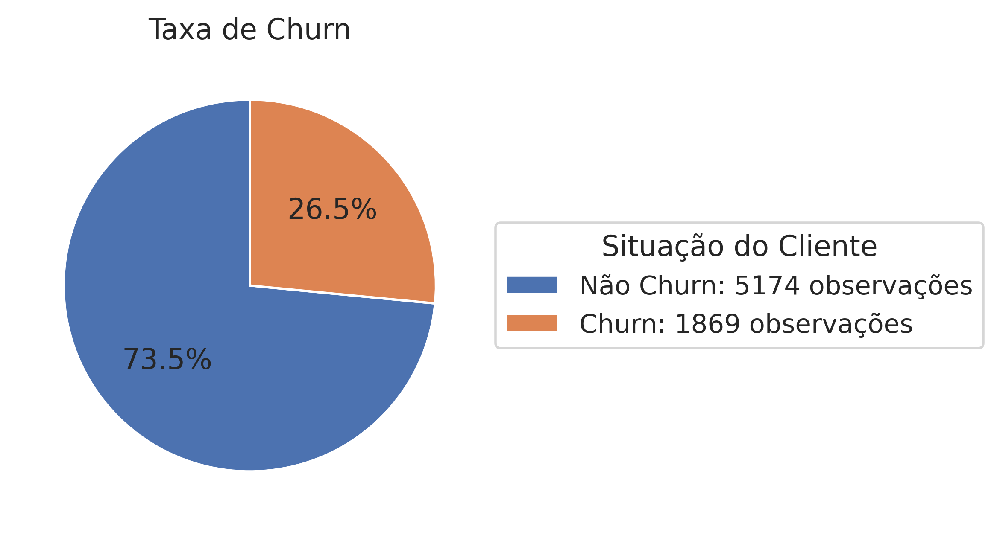

In [50]:
# Estilo seaborn
sns.set_theme(style="whitegrid")

# Contagem da variável target
target_counts = df[target].value_counts().sort_index()
sizes = target_counts.values

# Mapeamento semântico da target
label_map = {
    'No': 'Não Churn',
    'Yes': 'Churn'
}

# Plot
plt.figure(figsize=(6, 6))
wedges, _, autotexts = plt.pie(
    sizes,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white'}
)

# Legenda informativa
legend_labels = [
    f'{label_map[label]}: {count} observações'
    for label, count in zip(target_counts.index, sizes)
]

plt.legend(
    wedges,
    legend_labels,
    title='Situação do Cliente',
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)

plt.title('Taxa de Churn')
plt.tight_layout()
plt.show()

- O dataset está moderadamente desbalanceado, mas não é crítico
- O churn está alto, em torno de 1 em cada 4 clientes está saindo

## Motivo do Churn

In [51]:
## motivo de Churn
motivo_churn = df['Churn Reason'].value_counts(normalize=True) * 100
motivo_churn

Churn Reason
Attitude of support person                   10.272873
Competitor offered higher download speeds    10.112360
Competitor offered more data                  8.667737
Don't know                                    8.239700
Competitor made better offer                  7.490637
Attitude of service provider                  7.223114
Competitor had better devices                 6.955591
Network reliability                           5.510968
Product dissatisfaction                       5.457464
Price too high                                5.243446
Service dissatisfaction                       4.761905
Lack of self-service on Website               4.708400
Extra data charges                            3.049759
Moved                                         2.835741
Lack of affordable download/upload speed      2.354200
Limited range of services                     2.354200
Long distance charges                         2.354200
Poor expertise of phone support               1.0700

Agrupamento por motivos:
- Concorrência ~33%
  - Compeitor higher speed → 10.1%
  - Competitor more data → 8.7%
  - Competitor better offer → 7.5%
  - Competitor better devices → 7.0%
- Experiência ~17.5%
  - Attitude support → 10.3%
  - Attitude provider → 7.2%
- Produto / Qualidade ~15.8%
  - Network reliability → 5.5%
  - Product dissatisfaction → 5.5%
  - Service dissatisfaction → 4.8%
- Preço / Cobrança ~10.5%
  - Price too high → 5.2%
  - Extra data charges → 3.0%
  - Long distance charges → 2.3%
- Outros
  - Don't know → 8.2%
  - Moved → 2.8%
  - Deceased → irrelevante

Conclusão
- O churn não é dominado por preço, é dominado por concorrência + experiência
- ~1/3 dos churns são por concorrência direta
- Atendimento ruim pesa tanto quanto preço

# Análise de Correlação/Associação

## PairPlot

In [52]:
df_pair = df[num_vars].copy()
df_pair['Churn'] = df[target]
df_pair.drop('Churn Value', axis=1, inplace=True)
df_pair

,Tenure Months,Monthly Charges,Total Charges,Churn Score,CLTV,Churn
0,2,53.85,108.15,86,3239,Yes
1,2,70.70,151.65,67,2701,Yes
2,8,99.65,820.50,86,5372,Yes
3,28,104.80,3046.05,84,5003,Yes
4,49,103.70,5036.30,89,5340,Yes
...,...,...,...,...,...,...
7038,72,21.15,1419.40,45,5306,No
7039,24,84.80,1990.50,59,2140,No
7040,72,103.20,7362.90,71,5560,No
7041,11,29.60,346.45,59,2793,No


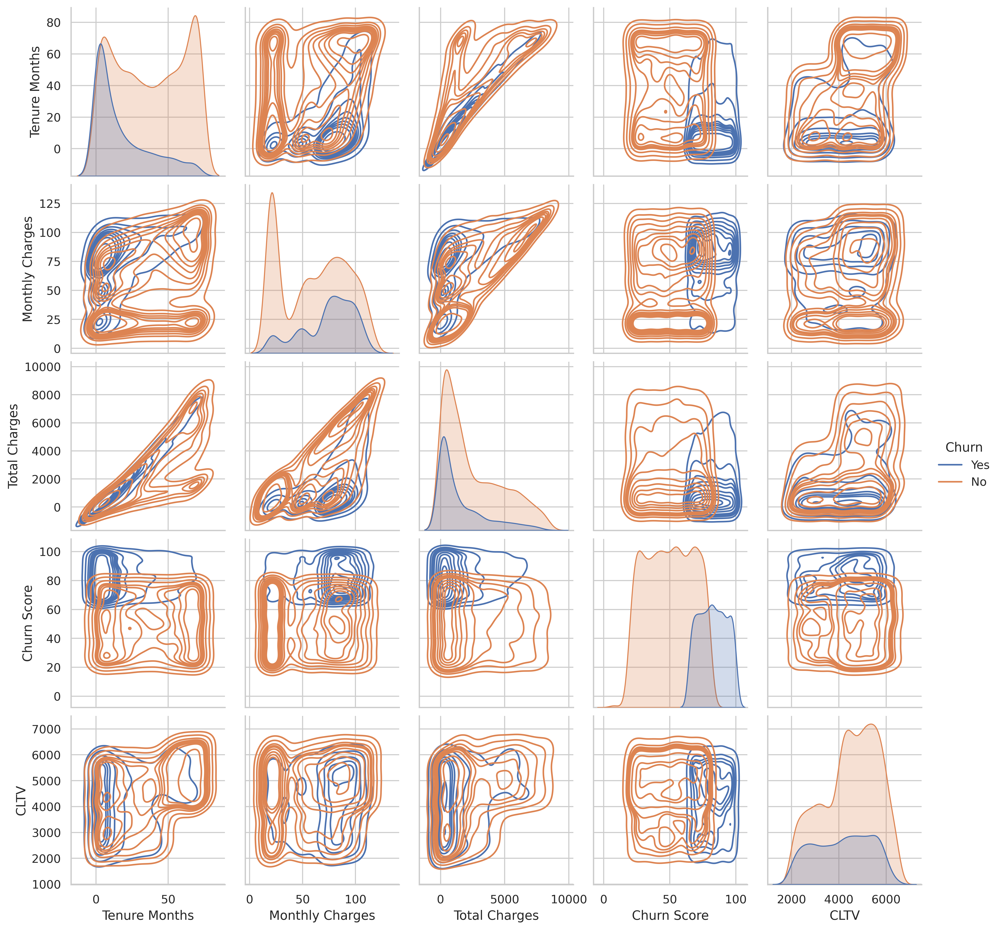

In [53]:
sns.pairplot(df_pair, hue='Churn', kind='kde')

## Matriz de Correlação

<Axes: >

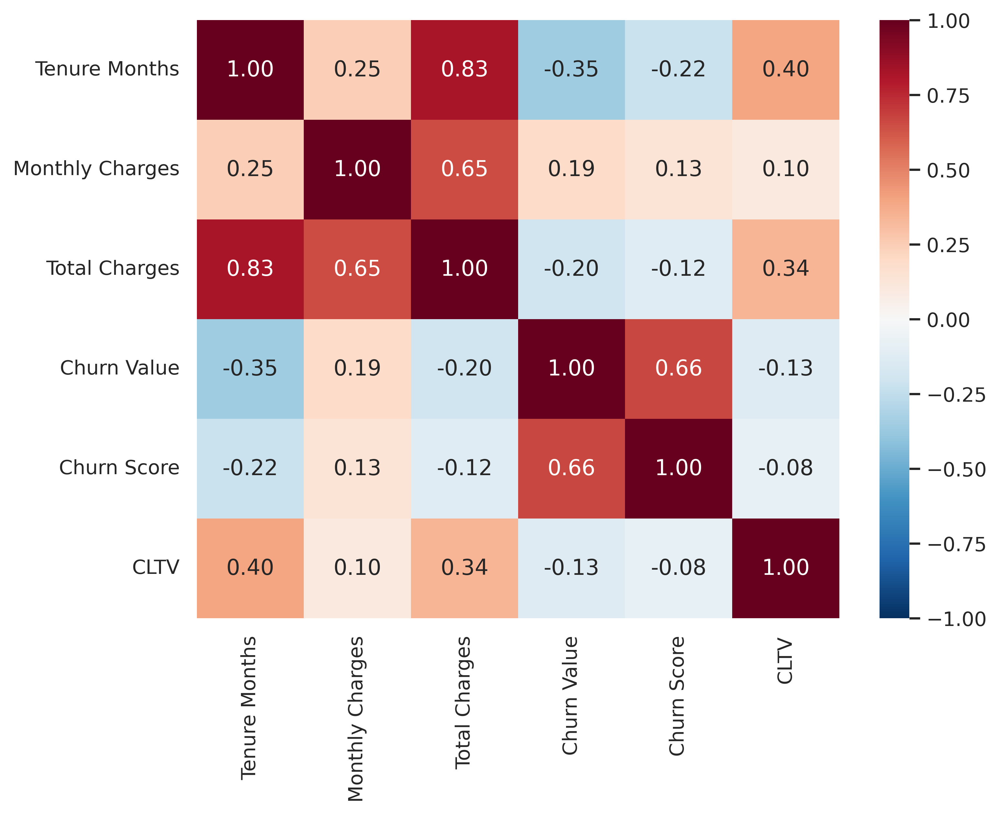

In [54]:
fig = plt.figure(figsize=(8,6))
sns.heatmap(df[num_vars].corr(),
            fmt=".2f",
            cmap='RdBu_r',
            vmin=-1, vmax=1,
            annot=True)

## Análise de Multicolinearidade - VIF

In [62]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(df: pd.DataFrame, features: list) -> pd.DataFrame:
    """
    Calcula o VIF (Variance Inflation Factor) para variáveis numéricas.

    Retorna DataFrame com VIF por variável, ordenado de forma decrescente.
    """
    X = df[features].dropna()
    vif_df = pd.DataFrame()
    vif_df["variavel"] = X.columns
    vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_df.sort_values("VIF", ascending=False).reset_index(drop=True)

def classify_vif(vif_df: pd.DataFrame) -> pd.DataFrame:
    """
    Classifica o grau de multicolinearidade com base no VIF:
    - VIF < 5       : Baixa
    - 5 ≤ VIF < 10  : Moderada
    - VIF ≥ 10      : Alta
    """
    conditions = [
        vif_df["VIF"] < 5,
        (vif_df["VIF"] >= 5) & (vif_df["VIF"] < 10),
        vif_df["VIF"] >= 10,
    ]
    choices = [
        "Baixa multicolinearidade",
        "Multicolinearidade moderada",
        "Alta multicolinearidade",
    ]
    vif_df = vif_df.copy()
    vif_df["classificacao"] = np.select(conditions, choices, default="Indefinido")
    return vif_df

vif_df = calculate_vif(df, num_vars)
vif_df = classify_vif(vif_df)
vif_df

,variavel,VIF,classificacao
0,Count,15076.320078,Alta multicolinearidade
1,Total Charges,9.744505,Multicolinearidade moderada
2,Latitude,8.431464,Multicolinearidade moderada
3,Tenure Months,5.984889,Multicolinearidade moderada
4,Zip Code,5.067917,Multicolinearidade moderada
5,Longitude,4.326434,Baixa multicolinearidade
6,Monthly Charges,3.534182,Baixa multicolinearidade
7,Churn Value,2.089641,Baixa multicolinearidade
8,Churn Score,1.793322,Baixa multicolinearidade
9,CLTV,1.189739,Baixa multicolinearidade


## Information Value (IV)

In [ ]:
target = 'Churn Value'
df_iv = AnaliseIV(df[cat_vars + [target]], target=target, convention="good_over_bad")
df_iv.get_lista_iv()

,Variavel,IV,Forca_Preditiva
0,Gender,-0.000,Irrelevante
1,Phone Service,-0.001,Irrelevante
2,Multiple Lines,-0.008,Irrelevante
3,Senior Citizen,-0.106,Irrelevante
4,Partner,-0.119,Irrelevante
5,Paperless Billing,-0.203,Irrelevante
6,Streaming TV,-0.380,Irrelevante
7,Streaming Movies,-0.381,Irrelevante
8,Payment Method,-0.457,Irrelevante
9,Dependents,-0.459,Irrelevante


In [ ]:
df_iv.get_bivariada('City')

Churn Value,Var_Range,NonEvent,Event,Total,Dist_Event,Dist_NonEvent,WOE,IV,Variavel
0,Acampo,1,3,4,0.001605,0.000193,-2.116855,-0.002989,City
1,Acton,4,0,4,0.000001,0.000773,6.650404,-0.005135,City
2,Adelanto,4,1,5,0.000535,0.000773,0.368052,-0.000088,City
3,Adin,2,2,4,0.001070,0.000387,-1.018243,-0.000696,City
4,Agoura Hills,3,2,5,0.001070,0.000580,-0.612777,-0.000300,City
...,...,...,...,...,...,...,...,...,...
1124,Yreka,4,0,4,0.000001,0.000773,6.650404,-0.005135,City
1125,Yuba City,6,2,8,0.001070,0.001160,0.080370,-0.000007,City
1126,Yucaipa,3,1,4,0.000535,0.000580,0.080370,-0.000004,City
1127,Yucca Valley,5,0,5,0.000001,0.000966,6.873547,-0.006636,City


In [ ]:
df_iv.get_bivariada('Contract')

Churn Value,Var_Range,NonEvent,Event,Total,Dist_Event,Dist_NonEvent,WOE,IV,Variavel
0,Month-to-month,2220,1655,3875,0.885500,0.429068,-0.724536,-0.330701,Contract
1,One year,1307,166,1473,0.088818,0.252609,1.045259,-0.171205,Contract
2,Two year,1647,48,1695,0.025682,0.318322,2.517267,-0.736654,Contract


## Qui-Quadrado + V de Cramer para variáveis categóricas

In [ ]:
resultado = chi2_analysis(df, cat_vars, target='Churn Value')

display(resultado)

,Variavel,Chi2,p_value,Cramer_V,Significancia,Forca_Associacao,Insight
0,City,1233.567219,1.497540e-02,0.418507,Significativo,Moderado,Boa variável preditiva
1,Contract,1184.596572,5.863038e-258,0.410116,Significativo,Moderado,Boa variável preditiva
2,Online Security,849.998968,2.661150e-185,0.347400,Significativo,Moderado,Boa variável preditiva
3,Tech Support,828.197068,1.443084e-180,0.342916,Significativo,Moderado,Boa variável preditiva
4,Internet Service,732.309590,9.571788e-160,0.322455,Significativo,Moderado,Boa variável preditiva
5,Payment Method,648.142327,3.682355e-140,0.303359,Significativo,Moderado,Boa variável preditiva
6,Online Backup,601.812790,2.079759e-131,0.292316,Significativo,Fraco,"Relação existe, mas fraca"
7,Device Protection,558.419369,5.505219e-122,0.281580,Significativo,Fraco,"Relação existe, mas fraca"
8,Dependents,433.734379,2.500972e-96,0.248161,Significativo,Fraco,"Relação existe, mas fraca"
9,Streaming Movies,375.661479,2.667757e-82,0.230951,Significativo,Fraco,"Relação existe, mas fraca"


# Árvore de Decisão para análise de importância de variáveis

## Preparando os Dados

### Variáveis Dummy

In [ ]:
cat_vars.remove('City')
num_vars.remove('Churn Score')

In [ ]:
dummy_vars = pd.get_dummies(df[cat_vars], drop_first=True, dtype=int)
dummy_vars.head()

,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_Fiber optic,Internet Service_No,Online Security_No internet service,Online Security_Yes,Online Backup_No internet service,Online Backup_Yes,Device Protection_No internet service,Device Protection_Yes,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,1,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
2,0,0,0,1,1,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,1,0
3,0,0,1,1,1,0,1,1,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,1,0,1,0
4,1,0,0,1,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,1,0,0,0


### df_final

In [ ]:
df_final = pd.concat([df[num_vars], dummy_vars], axis=1)
df_final.head()

,Tenure Months,Monthly Charges,Total Charges,Churn Value,CLTV,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_Fiber optic,Internet Service_No,Online Security_No internet service,Online Security_Yes,Online Backup_No internet service,Online Backup_Yes,Device Protection_No internet service,Device Protection_Yes,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,2,53.85,108.15,1,3239,1,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
1,2,70.70,151.65,1,2701,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
2,8,99.65,820.50,1,5372,0,0,0,1,1,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,1,0
3,28,104.80,3046.05,1,5003,0,0,1,1,1,0,1,1,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,1,0,1,0
4,49,103.70,5036.30,1,5340,1,0,0,1,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,1,0,0,0


### Separando X e y

In [ ]:
# features
X = df_final.drop(columns=[target])

# target
y = df_final[target]

## Plotando a Árvore de Decisão

In [ ]:
exploratory_tree = DecisionTreeClassifier(
    #max_depth = 3,
    min_samples_leaf=50,
    random_state = 42
)


exploratory_tree.fit(X,y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curren

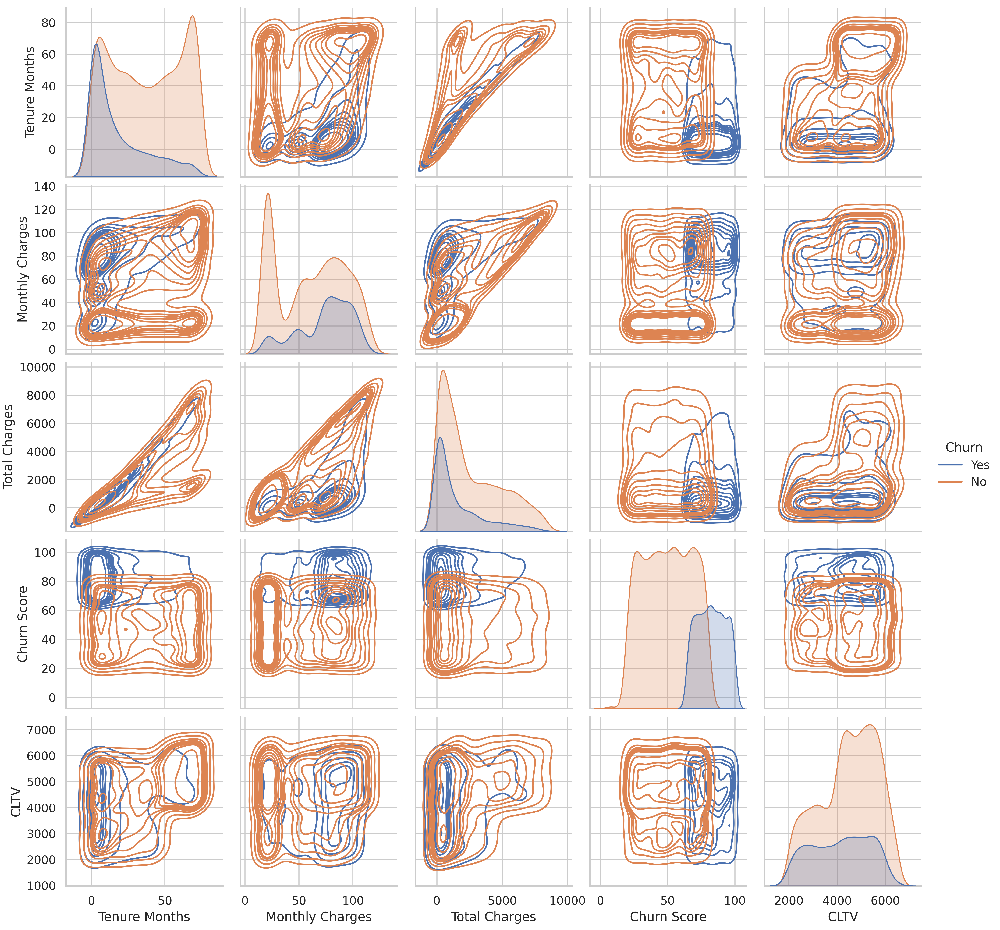

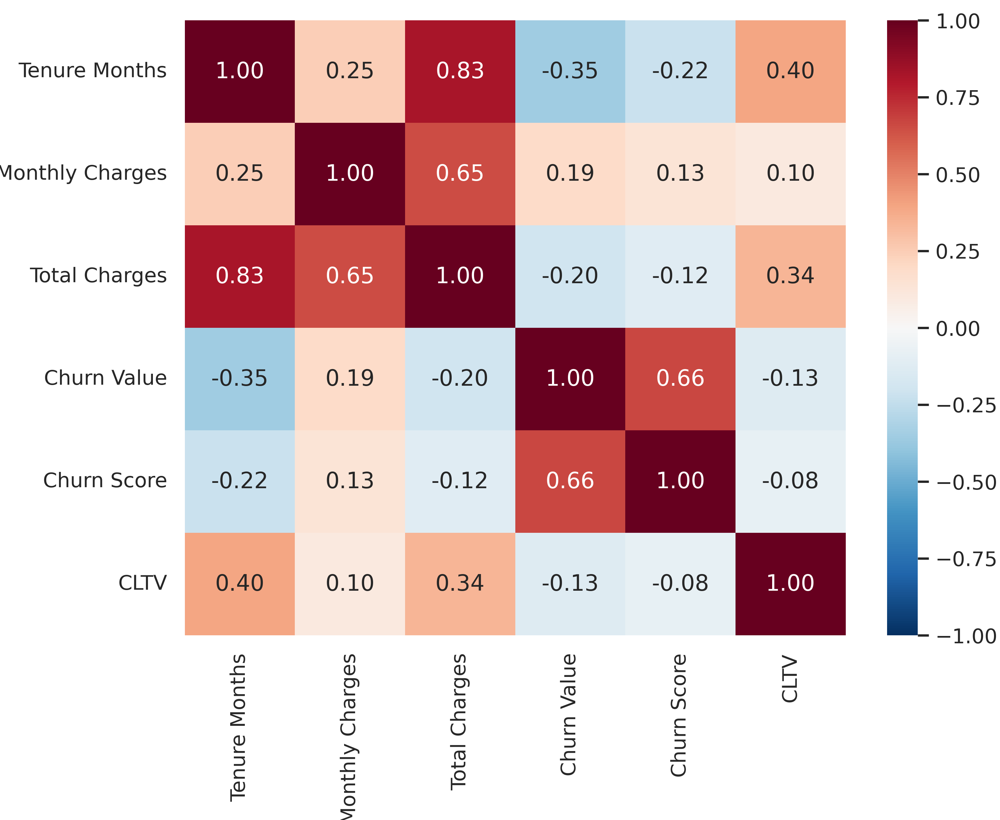

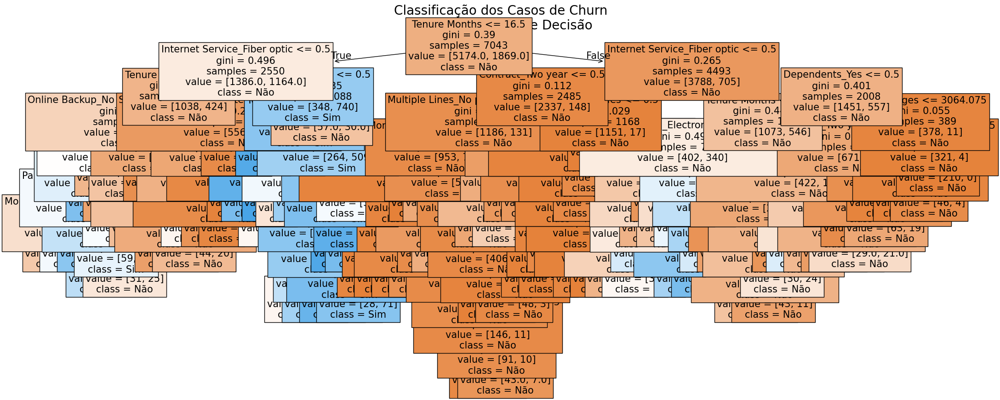

In [ ]:
# visualizando a arvore
from sklearn import tree
sns.reset_defaults()
fig = plt.figure(figsize=(25, 10))
feature_names = X.columns.to_list()
tree.plot_tree(exploratory_tree, feature_names=feature_names, filled=True, class_names=['Não', 'Sim'], fontsize=15);

plt.title('Classificação dos Casos de Churn\n usando a Arvore de Decisão', fontsize=20)
plt.show()

## Features Importance

In [ ]:
importances = np.asarray(exploratory_tree.feature_importances_).ravel()  # garante numpy 1D
features = list(X.columns)

df_imp = pd.DataFrame({
    "feature": features,
    "importance": importances
})


df_imp["importance"] = pd.to_numeric(df_imp["importance"], errors="coerce")
n_nulls = df_imp["importance"].isna().sum()
if n_nulls > 0:
    print(f"Atenção: {n_nulls} importances viraram NaN ao converter para numérico. Confira o modelo/importances.")


df_imp = df_imp.sort_values(by="importance", ascending=False, kind="quicksort").reset_index(drop=True)
df_imp

,feature,importance
0,Tenure Months,0.371946
1,Internet Service_Fiber optic,0.290327
2,Dependents_Yes,0.085406
3,Monthly Charges,0.040857
4,Total Charges,0.040756
5,Online Backup_No internet service,0.025054
6,Contract_Two year,0.022423
7,Payment Method_Electronic check,0.022188
8,CLTV,0.019133
9,Contract_One year,0.013918


# Principais Drivers de Churn

Tier 1 - (core drivers)
- Tenure Months
- Contract
- Internet Service
- Online Security
- Tech Support

Tier 2 - (relevantes)
- Dependents
- Payment Method
- Online Backup
- Device Protection

Tier 3 - (Moderados)
- Monthly Charges
- Paperless Billing
- Partner
- Senior Citizen

Tier 4 - (Irrelevantes)
- Gender
- Phone Service
- Multiple Lines

# Principais Conclusões

- A atual taxa de Churn é de **26,6%**;
- A função de risco de churn é **decrescente no tempo**, ou seja, quanto mais o tempo passa, menor o risco de churn;
- Churn é sensível ao preço (monthly charge), mas não é linear. Preço alto, aumenta o churn. Porém, clientes antigos toleram preço alto, enquanto clientes novos não;
- O tipo de Contrato atua como um mitigador de churn. Contratos anuais tem taxas de churn muito inferiores quando comparadas a contratos mensais;
- Entre os principais motivos de churn, a má experiência com o suporte da empresa foi fator decisivo em, aproximadamente, 20% dos casos;
- A concorrência oferecer melhores valores e serviços, foi responsável por cerca de 35% dos motivos de churn;
- Cerca de 25% dos motivos de Churn, estão relacionados ao mismatch entre expecativa e entrega do serviço contratado;
- A variável `City`apresenta alta granularidade e precisa ser transformada via feature engineering para ser incluida no modelo;
- `Churn Score` e `CLTV` precisam ser avaliadas com cuidado sob risco de leakage;
- `Total Charges`, `Tenure Months`, `Monthly Charges`, `CLTV` e `Churn Score` tiveram um alto vif, resultando em alta multicolinearide;

# Sugestões para Feature Engineering

1. Clusterização das Cidades em Regiões para ajudar a reduzir incidencia de classes raras com um único cenário;
2. Cluster de Engajamento Digital (Scorer de Engajamento de Serviços);
3. Flag Ternure_Group para extratificação de clientes novos e antigos - churn não é linear no tempo;
4. Proxy de percepção de custo;
5. Codificação Ordinal na variável de Contrato seguindo critério monotônico;
6. Flag de estabilidade familiar identificando quais casos os clientes possuem dependentes ou planos familiares;

# Próximos Passos

- Preenchimento do ML Canvas do projeto;
- Elaboração do MVP (baseline);